In [1]:
import numpy as np
import matplotlib.pyplot as plt

from recovery import baseline_recovery_kraus
from codes import leung_isometry
from channels import noisy_kraus_operator 
from petz import completed_petz_kraus
from fidelity import entanglement_fidelity

In [2]:
V =leung_isometry()
bits = [format(i, '04b') for i in range(16)]
noisy_kraus = lambda gamma : [noisy_kraus_operator(bit, gamma) for bit in bits]
noisy_encoding_kraus = lambda gamma : [N@V for N in noisy_kraus(gamma)]
R = baseline_recovery_kraus()
R_til = lambda gamma : completed_petz_kraus(np.eye(2)/2 , gamma)
baseline_recov = lambda gamma : [r@E for r in R for E in noisy_encoding_kraus(gamma)]
petz_recove = lambda gamma : [r_til@E for r_til in R_til(gamma) for E in noisy_encoding_kraus(gamma)]

fidelity_baseline = lambda gamma : entanglement_fidelity(baseline_recov(gamma))
fidelity_recov = lambda gamma : entanglement_fidelity(petz_recove(gamma))

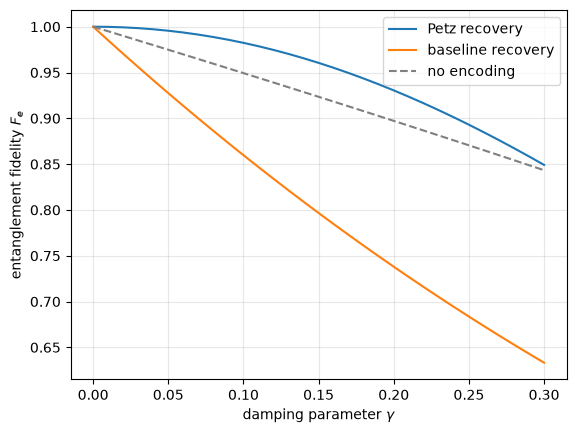

In [4]:
gamma = np.linspace(0, 0.3, 31)                     
f_b = [fidelity_baseline(g) for g in gamma]
f_p = [fidelity_recov(g) for g in gamma]
f_none = (1 + np.sqrt(1 - gamma))**2 / 4            

plt.plot(gamma, f_p, label="Petz recovery")
plt.plot(gamma, f_b, label="baseline recovery")
plt.plot(gamma, f_none, "--", color="gray", label="no encoding")
plt.xlabel(r"damping parameter $\gamma$")
plt.ylabel(r"entanglement fidelity $F_e$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Discussion: Petz vs. baseline recovery

### 1. How quickly does the fidelity decrease as $\gamma$ increases?

For small $\gamma$: $1 - F_{\text{baseline}} \approx 1.5\,\gamma$, while $1 - F_{\text{Petz}} \approx 1.75\,\gamma^2$. The baseline loses fidelity at first order in $\gamma$, Petz only at second order, so Petz decreases much more slowly.

### 2. Does Petz outperform the baseline?

Yes, at every $\gamma > 0$ tested. At $\gamma = 0.3$: $F_{\text{Petz}} = 0.849$ against $F_{\text{baseline}} = 0.633$. The baseline is even worse than not encoding at all ($F = (1+\sqrt{1-\gamma})^2/4$), because it exposes 4 qubits to noise instead of 1 without correcting anything.

### 3. How does the difference evolve with $\gamma$?

The gap grows with $\gamma$, roughly like $1.5\,\gamma$ at first (0.068 at $\gamma = 0.05$, 0.123 at $\gamma = 0.1$, 0.216 at $\gamma = 0.3$). It only shrinks for much larger $\gamma$ (beyond our plot), where both methods fail.

### 4. Why can a noise-aware decoder beat projecting onto the code space?

A single decay sends $\lvert 0_L\rangle$ and $\lvert 1_L\rangle$ outside the code space, but to two orthogonal states that depend on which qubit decayed. The logical information is moved, not destroyed, so it can be recovered.

- The **baseline** only looks inside the code space: after a single decay it outputs $I/2$ and loses everything. That's why it fails at first order in $\gamma$.
- The **Petz map** is built from the noise's Kraus operators, so it knows where each error sends the code and maps it back. Single decays are corrected, and only errors of order $\gamma^2$ (two decays, small distortion of the no-decay branch) remain. That's why the code is an *approximate* error-correcting code.
